Saving customer_churn.csv to customer_churn.csv
Data loaded: 500 rows and 9 columns
Missing values: 0 | Customers who left: 53 (10.6%)

DAY 1: CHOOSING WHAT TO CLUSTER ON
Clustering features: MonthlyCharges (how much the customer spends)
                     Contract_ordinal (how committed the customer is: 0, 1 or 2)
Why these two: they describe the customer's VALUE and COMMITMENT, which a company can act on.
Tenure is NOT used for clustering: it is tied to churn, so segments should describe who the
customer is, and churn is predicted INSIDE each segment (Tenure is used there).
Yes/no columns (SeniorCitizen, PaperlessBilling) were tested too: they only split the data
into arbitrary yes/no groups and made the segments harder to explain.

ELBOW METHOD AND SILHOUETTE SCORE
 k (clusters)  Inertia  Silhouette
            2    621.0       0.364
            3    370.0       0.438
            4    250.0       0.453
            5    179.0       0.506
            6    121.0       0.557
         

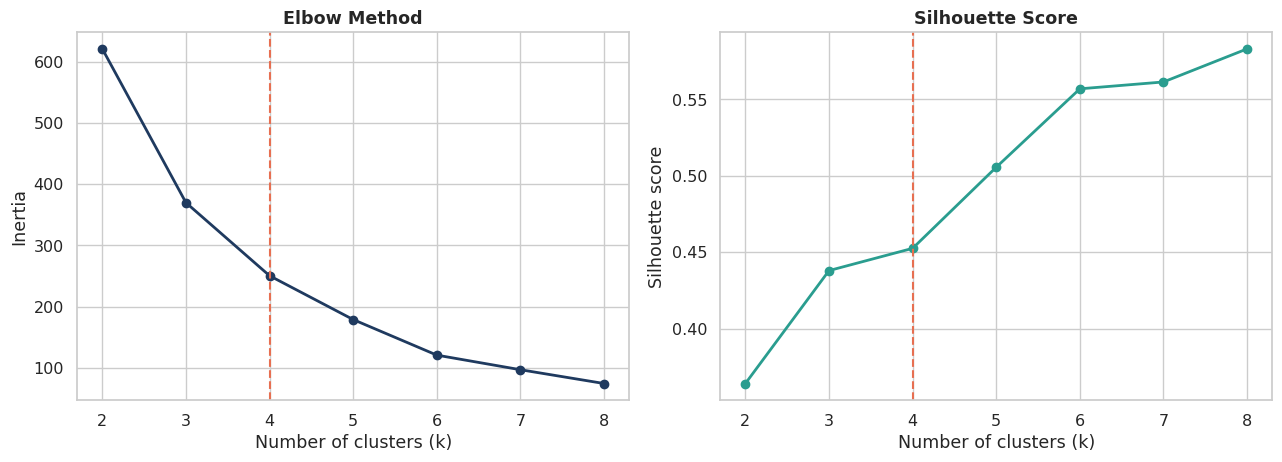

Choice: k = 4.
  - The elbow has no sharp bend; the curve flattens gradually after 3 to 4 clusters.
  - Silhouette keeps rising with k because Contract has only 3 values, so more clusters look 'cleaner'.
  - 4 clusters give groups that are large enough to model and easy to explain.

K-MEANS RESULT (k = 4)
                Customers  Left  Churn_rate  Avg_monthly_charge  Avg_contract  Avg_tenure
KMeans_cluster                                                                           
0                     100    23        23.0               148.5           0.0        36.6
1                      82     3         3.7                73.9           2.0        35.7
2                     162    14         8.6               160.5           1.4        35.8
3                     156    13         8.3                63.5           0.6        37.7

Contract: 0 = month-to-month, 1 = one year, 2 = two year.
Silhouette score for k = 4: 0.453
Check the 'Left' column: one cluster has very few customers 

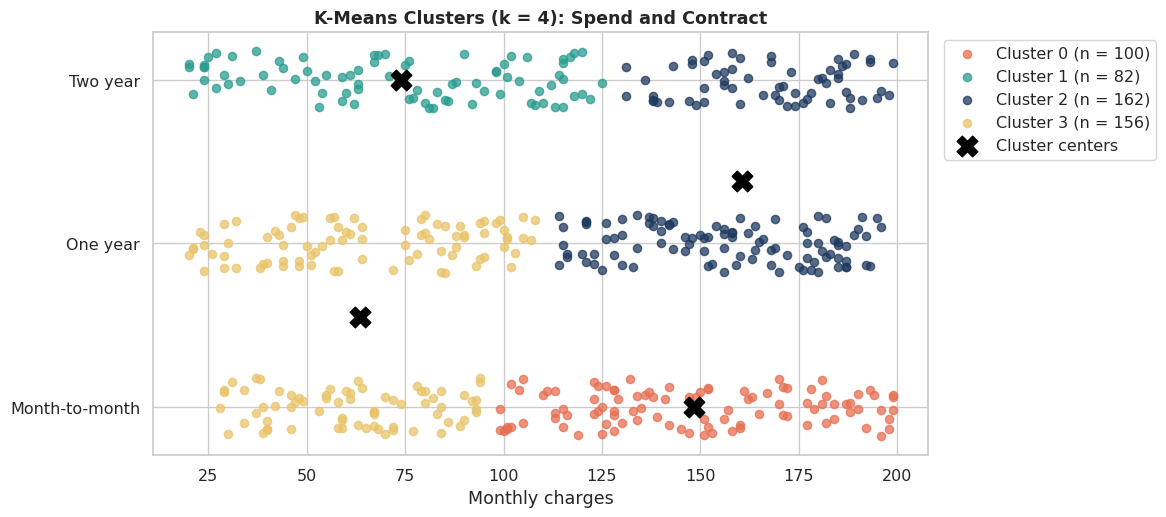

In [2]:
# Week 11: Customer Segmentation and Prediction
# Part 1: Prepare the data and apply K-Means clustering (Day 1)

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style='whitegrid', font_scale=1.05)
os.makedirs('figures', exist_ok=True)
TEAL, ORANGE, NAVY, GREY, GOLD = '#2a9d8f', '#e76f51', '#1f3a5f', '#9aa5b1', '#e9c46a'
SEGMENT_COLORS = [ORANGE, TEAL, NAVY, GOLD]

# ---------- Load the data (upload customer_churn.csv) ----------
uploaded = files.upload()
file_name = None
for name in uploaded:
    if 'churn' in name.lower() or 'customer' in name.lower():
        file_name = name

if file_name is None:
    print("Error: please upload the customer churn file (customer_churn.csv).")
else:
    df = pd.read_csv(file_name)
    print("Data loaded:", df.shape[0], "rows and", df.shape[1], "columns")
    print("Missing values:", int(df.isnull().sum().sum()), "| Customers who left:", int(df['Churn'].sum()),
          f"({df['Churn'].mean() * 100:.1f}%)")

    # ---------- Prepare the columns used for clustering ----------
    df['Contract_ordinal'] = df['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})
    df['PaperlessBilling_binary'] = (df['PaperlessBilling'] == 'Yes').astype(int)

    print()
    print("=" * 60)
    print("DAY 1: CHOOSING WHAT TO CLUSTER ON")
    print("=" * 60)
    print("Clustering features: MonthlyCharges (how much the customer spends)")
    print("                     Contract_ordinal (how committed the customer is: 0, 1 or 2)")
    print("Why these two: they describe the customer's VALUE and COMMITMENT, which a company can act on.")
    print("Tenure is NOT used for clustering: it is tied to churn, so segments should describe who the")
    print("customer is, and churn is predicted INSIDE each segment (Tenure is used there).")
    print("Yes/no columns (SeniorCitizen, PaperlessBilling) were tested too: they only split the data")
    print("into arbitrary yes/no groups and made the segments harder to explain.")

    cluster_cols = ['MonthlyCharges', 'Contract_ordinal']
    scaler = StandardScaler()
    X_cluster = scaler.fit_transform(df[cluster_cols])                    # same scale for both columns

    # ---------- Elbow method and silhouette score for k = 2 to 8 ----------
    ks = list(range(2, 9))
    inertia, silhouette = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_cluster)
        inertia.append(km.inertia_)
        silhouette.append(silhouette_score(X_cluster, km.labels_))

    print()
    print("=" * 60)
    print("ELBOW METHOD AND SILHOUETTE SCORE")
    print("=" * 60)
    print(pd.DataFrame({'k (clusters)': ks, 'Inertia': np.round(inertia, 0), 'Silhouette': np.round(silhouette, 3)}).to_string(index=False))
    print("Inertia = how spread out the points are inside their clusters (lower is tighter).")
    print("Silhouette = how well separated the clusters are (1 is best, 0 means overlapping).")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    axes[0].plot(ks, inertia, marker='o', color=NAVY, linewidth=2)
    axes[0].axvline(4, color=ORANGE, linestyle='--')
    axes[0].set_title('Elbow Method', fontweight='bold')
    axes[0].set_xlabel('Number of clusters (k)')
    axes[0].set_ylabel('Inertia')
    axes[1].plot(ks, silhouette, marker='o', color=TEAL, linewidth=2)
    axes[1].axvline(4, color=ORANGE, linestyle='--')
    axes[1].set_title('Silhouette Score', fontweight='bold')
    axes[1].set_xlabel('Number of clusters (k)')
    axes[1].set_ylabel('Silhouette score')
    plt.tight_layout()
    plt.savefig('figures/1_elbow_silhouette.png', dpi=150, bbox_inches='tight')
    plt.show()

    # ---------- Choose k = 4 and fit K-Means ----------
    print("Choice: k = 4.")
    print("  - The elbow has no sharp bend; the curve flattens gradually after 3 to 4 clusters.")
    print("  - Silhouette keeps rising with k because Contract has only 3 values, so more clusters look 'cleaner'.")
    print("  - 4 clusters give groups that are large enough to model and easy to explain.")
    kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_cluster)
    df['KMeans_cluster'] = kmeans.labels_

    print()
    print("=" * 60)
    print("K-MEANS RESULT (k = 4)")
    print("=" * 60)
    summary = df.groupby('KMeans_cluster').agg(Customers=('Churn', 'size'), Left=('Churn', 'sum'),
                                               Churn_rate=('Churn', 'mean'), Avg_monthly_charge=('MonthlyCharges', 'mean'),
                                               Avg_contract=('Contract_ordinal', 'mean'), Avg_tenure=('Tenure', 'mean'))
    summary['Churn_rate'] = (summary['Churn_rate'] * 100).round(1)
    print(summary.round(1).to_string())
    print()
    print("Contract: 0 = month-to-month, 1 = one year, 2 = two year.")
    print(f"Silhouette score for k = 4: {silhouette_score(X_cluster, kmeans.labels_):.3f}")
    print("Check the 'Left' column: one cluster has very few customers who left. That matters for Part 4.")

    rng = np.random.default_rng(42)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for c in range(4):
        part = df[df['KMeans_cluster'] == c]
        ax.scatter(part['MonthlyCharges'], part['Contract_ordinal'] + rng.uniform(-0.18, 0.18, len(part)),
                   s=35, alpha=0.75, color=SEGMENT_COLORS[c], label=f'Cluster {c} (n = {len(part)})')
    centers = scaler.inverse_transform(kmeans.cluster_centers_)
    ax.scatter(centers[:, 0], centers[:, 1], marker='X', s=220, color='black', label='Cluster centers')
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(['Month-to-month', 'One year', 'Two year'])
    ax.set_xlabel('Monthly charges')
    ax.set_title('K-Means Clusters (k = 4): Spend and Contract', fontweight='bold')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    plt.savefig('figures/2_kmeans_clusters.png', dpi=150, bbox_inches='tight')
    plt.show()

ALGORITHM 2: HIERARCHICAL CLUSTERING (Ward)


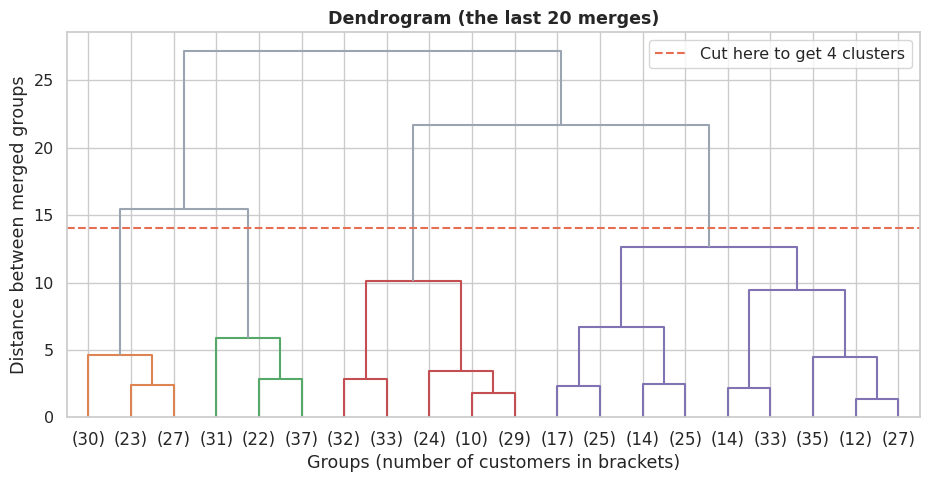

Customers per hierarchical cluster: {0: 202, 1: 90, 2: 128, 3: 80}
The tall jumps at the top of the dendrogram show where merging starts to join very different groups.

ALGORITHM 3: DBSCAN (min_samples = 5)
 eps (reach)  Clusters found  Noise points  Silhouette
        0.15               4             0       0.324
        0.30               3             0       0.367
        0.50               3             0       0.367
        0.80               3             0       0.367
        1.20               3             0       0.367

DBSCAN with eps = 0.5 customers per cluster: {0: 186, 1: 170, 2: 144}
Agreement between DBSCAN clusters and the 3 contract types (1.0 = identical): 1.00
DBSCAN only finds the 3 contract types. MonthlyCharges is spread evenly with no dense groups or gaps,
so density cannot split customers by spend. DBSCAN is less useful for this data.

COMPARISON OF THE THREE ALGORITHMS
           Algorithm  Clusters  Silhouette (higher is better)  Davies-Bouldin (lower is be

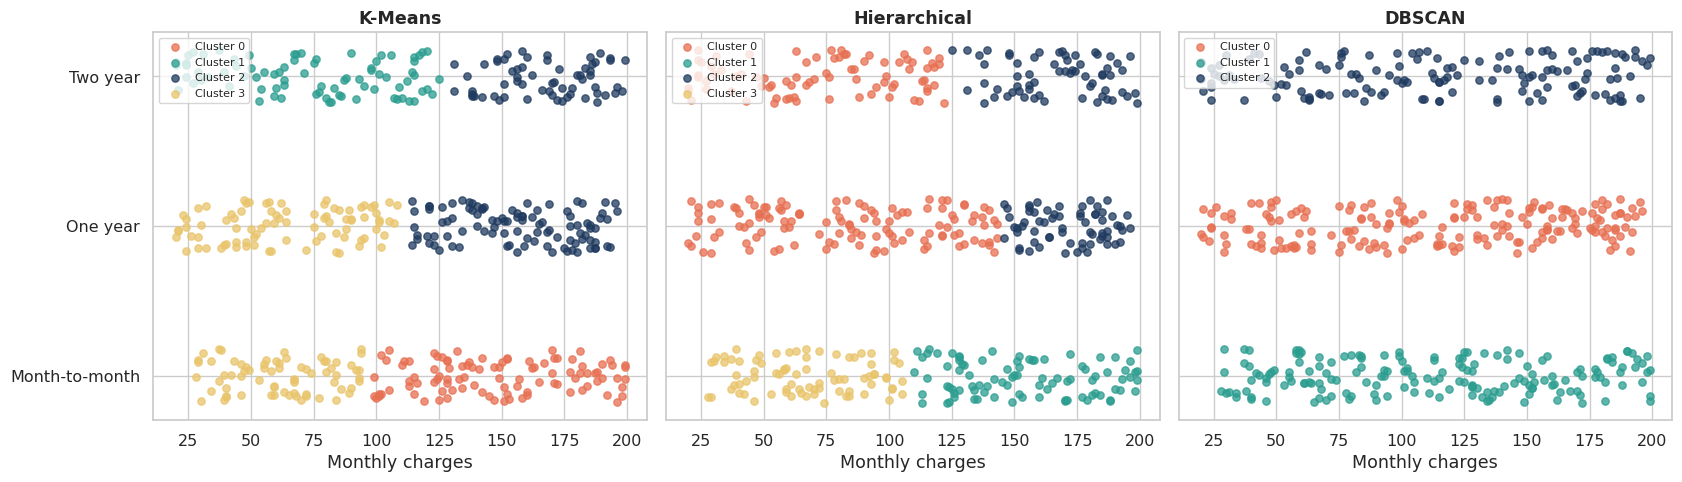

In [3]:
# Part 2: Hierarchical clustering and DBSCAN, then compare all three algorithms (Day 2)

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

# =====================================================================
# ALGORITHM 2: HIERARCHICAL CLUSTERING (Ward linkage)
# Starts with every customer alone, then keeps merging the two closest groups.
# =====================================================================
print("=" * 60)
print("ALGORITHM 2: HIERARCHICAL CLUSTERING (Ward)")
print("=" * 60)
merge_tree = linkage(X_cluster, method='ward')
cut_height = (merge_tree[-3, 2] + merge_tree[-4, 2]) / 2                 # a cut between the last 3 and 4 merges gives 4 clusters
fig, ax = plt.subplots(figsize=(11, 5))
dendrogram(merge_tree, truncate_mode='lastp', p=20, ax=ax, color_threshold=cut_height,
           above_threshold_color=GREY)
ax.axhline(cut_height, color=ORANGE, linestyle='--', label='Cut here to get 4 clusters')
ax.set_title('Dendrogram (the last 20 merges)', fontweight='bold')
ax.set_xlabel('Groups (number of customers in brackets)')
ax.set_ylabel('Distance between merged groups')
ax.legend()
plt.savefig('figures/3_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

hier = AgglomerativeClustering(n_clusters=4, linkage='ward')
df['Hierarchical_cluster'] = hier.fit_predict(X_cluster)
print("Customers per hierarchical cluster:", df['Hierarchical_cluster'].value_counts().sort_index().to_dict())
print("The tall jumps at the top of the dendrogram show where merging starts to join very different groups.")

# =====================================================================
# ALGORITHM 3: DBSCAN (density-based)
# Groups points that are packed closely together; points far from everyone are 'noise'.
# =====================================================================
print()
print("=" * 60)
print("ALGORITHM 3: DBSCAN (min_samples = 5)")
print("=" * 60)
rows = []
for eps in [0.15, 0.3, 0.5, 0.8, 1.2]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_cluster)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    sil = silhouette_score(X_cluster, labels) if n_clusters >= 2 else np.nan
    rows.append([eps, n_clusters, int((labels == -1).sum()), sil])
print(pd.DataFrame(rows, columns=['eps (reach)', 'Clusters found', 'Noise points', 'Silhouette']).round(3).to_string(index=False))

dbscan = DBSCAN(eps=0.5, min_samples=5)
df['DBSCAN_cluster'] = dbscan.fit_predict(X_cluster)
print()
print("DBSCAN with eps = 0.5 customers per cluster:", df['DBSCAN_cluster'].value_counts().sort_index().to_dict())
same_as_contract = adjusted_rand_score(df['Contract_ordinal'], df['DBSCAN_cluster'])
print(f"Agreement between DBSCAN clusters and the 3 contract types (1.0 = identical): {same_as_contract:.2f}")
print("DBSCAN only finds the 3 contract types. MonthlyCharges is spread evenly with no dense groups or gaps,")
print("so density cannot split customers by spend. DBSCAN is less useful for this data.")

# =====================================================================
# COMPARE THE THREE ALGORITHMS
# =====================================================================
print()
print("=" * 60)
print("COMPARISON OF THE THREE ALGORITHMS")
print("=" * 60)
compare = []
for name, col in [('K-Means (k = 4)', 'KMeans_cluster'), ('Hierarchical (k = 4)', 'Hierarchical_cluster'),
                  ('DBSCAN (eps = 0.5)', 'DBSCAN_cluster')]:
    labels = df[col].values
    sizes = df.groupby(col).size()
    compare.append({'Algorithm': name, 'Clusters': len(sizes),
                    'Silhouette (higher is better)': silhouette_score(X_cluster, labels),
                    'Davies-Bouldin (lower is better)': davies_bouldin_score(X_cluster, labels),
                    'Calinski-Harabasz (higher is better)': calinski_harabasz_score(X_cluster, labels),
                    'Smallest cluster': int(sizes.min()), 'Largest cluster': int(sizes.max())})
print(pd.DataFrame(compare).round(3).to_string(index=False))
agreement = adjusted_rand_score(df['KMeans_cluster'], df['Hierarchical_cluster'])
print()
print(f"Agreement between K-Means and Hierarchical (1.0 = identical groups): {agreement:.2f}")
print()
print("Churners in each cluster (Left / Customers):")
for name, col in [('K-Means', 'KMeans_cluster'), ('Hierarchical', 'Hierarchical_cluster')]:
    g = df.groupby(col)['Churn'].agg(['sum', 'size'])
    print(f"  {name}: " + ", ".join(f"cluster {i}: {int(r['sum'])}/{int(r['size'])}" for i, r in g.iterrows()))
print()
print("DECISION: K-Means is used for the customer segments.")
print("  - It has the best separation scores of the three algorithms.")
print("  - Its groups are balanced in size and each has a clear centre (average spend and contract).")
print("  - Hierarchical gives similar but less balanced groups; DBSCAN only finds the contract types.")

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
rng = np.random.default_rng(42)
for ax, (title, col) in zip(axes, [('K-Means', 'KMeans_cluster'), ('Hierarchical', 'Hierarchical_cluster'),
                                   ('DBSCAN', 'DBSCAN_cluster')]):
    labels = sorted(df[col].unique())
    for i, lab in enumerate(labels):
        part = df[df[col] == lab]
        ax.scatter(part['MonthlyCharges'], part['Contract_ordinal'] + rng.uniform(-0.18, 0.18, len(part)), s=28, alpha=0.75,
                   color=SEGMENT_COLORS[i % 4] if lab != -1 else 'black', label=f'Cluster {lab}')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Monthly charges')
    ax.set_yticks([0, 1, 2])
    ax.set_yticklabels(['Month-to-month', 'One year', 'Two year'])
    ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('figures/4_algorithm_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

SEGMENT NAMES (from the cluster averages)
Rule: 'Premium' if the average monthly charge is above the overall average (113.6), otherwise 'Budget'.
      'Committed' if the average contract is one year or longer, otherwise 'Flexible' (month-to-month or short contracts).
  Cluster 0 -> Premium Flexible
  Cluster 1 -> Budget Committed
  Cluster 2 -> Premium Committed
  Cluster 3 -> Budget Flexible
All names are different: True

SEGMENT PROFILES (sorted from highest to lowest churn rate)
                   Customers  Share of customers %  Avg monthly charge  Avg tenure (months)
Segment                                                                                    
Premium Flexible         100                  20.0               148.5                 36.6
Premium Committed        162                  32.4               160.5                 35.8
Budget Flexible          156                  31.2                63.5                 37.7
Budget Committed          82                  16.4  

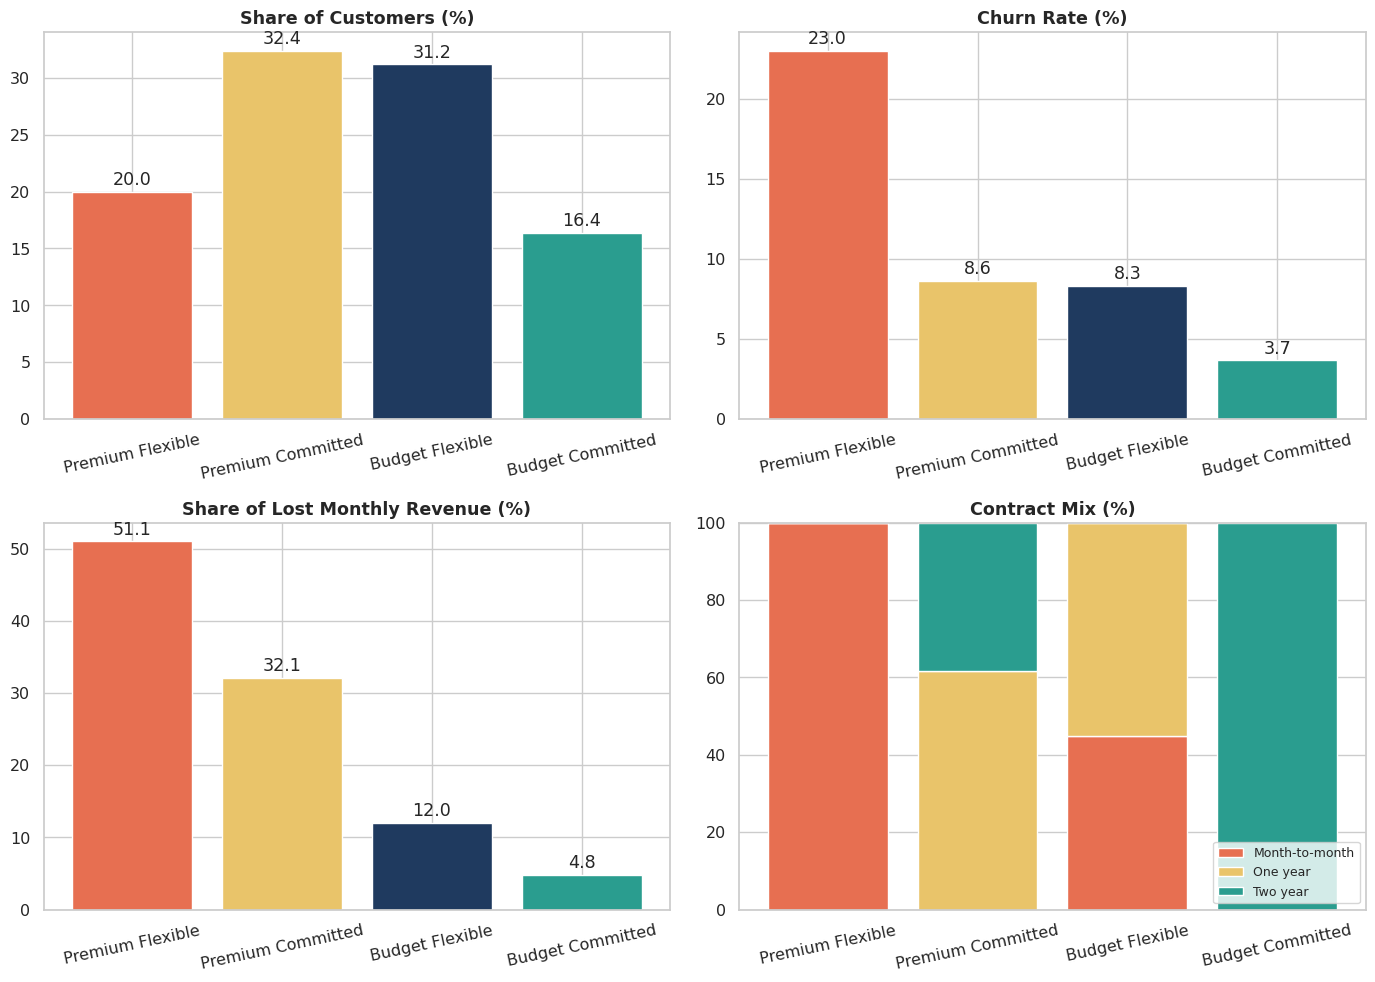

TESTS
Test 1: every customer has a segment -> True
Test 2: segment sizes add up to 500 customers (expected 500)
Test 3: contract percentages add up to 100 in every segment -> True
Test 4: customers who left add up to 53 (expected 53)
Saved segmentation_data.csv with 500 rows and 13 columns


In [4]:
# Part 3: Segment analysis - customer profiles and names (Day 3)

# ---------- Name each K-Means cluster from its average spend and contract ----------
overall_charge = df['MonthlyCharges'].mean()
cluster_means = df.groupby('KMeans_cluster').agg(charge=('MonthlyCharges', 'mean'), contract=('Contract_ordinal', 'mean'))

names = {}
for cluster, row in cluster_means.iterrows():
    spend = 'Premium' if row['charge'] > overall_charge else 'Budget'
    commitment = 'Committed' if row['contract'] >= 1.0 else 'Flexible'
    names[cluster] = f"{spend} {commitment}"
df['Segment'] = df['KMeans_cluster'].map(names)

print("=" * 60)
print("SEGMENT NAMES (from the cluster averages)")
print("=" * 60)
print(f"Rule: 'Premium' if the average monthly charge is above the overall average ({overall_charge:.1f}), otherwise 'Budget'.")
print("      'Committed' if the average contract is one year or longer, otherwise 'Flexible' (month-to-month or short contracts).")
for cluster, name in names.items():
    print(f"  Cluster {cluster} -> {name}")
print("All names are different:", len(set(names.values())) == 4)

# ---------- Build the profile of each segment ----------
total_revenue = df['MonthlyCharges'].sum()
lost_revenue_total = df.loc[df['Churn'] == 1, 'MonthlyCharges'].sum()
rows = []
for seg, g in df.groupby('Segment'):
    left = g[g['Churn'] == 1]
    rows.append({
        'Segment': seg,
        'Customers': len(g),
        'Share of customers %': len(g) / len(df) * 100,
        'Avg monthly charge': g['MonthlyCharges'].mean(),
        'Avg tenure (months)': g['Tenure'].mean(),
        'Month-to-month %': (g['Contract'] == 'Month-to-month').mean() * 100,
        'One year %': (g['Contract'] == 'One year').mean() * 100,
        'Two year %': (g['Contract'] == 'Two year').mean() * 100,
        'Paperless billing %': (g['PaperlessBilling'] == 'Yes').mean() * 100,
        'Senior citizens %': g['SeniorCitizen'].mean() * 100,
        'Electronic check %': (g['PaymentMethod'] == 'Electronic Check').mean() * 100,
        'Customers who left': len(left),
        'Churn rate %': g['Churn'].mean() * 100,
        'Monthly revenue': g['MonthlyCharges'].sum(),
        'Monthly revenue lost': left['MonthlyCharges'].sum(),
        'Share of revenue lost %': left['MonthlyCharges'].sum() / lost_revenue_total * 100})
profiles = pd.DataFrame(rows).sort_values('Churn rate %', ascending=False).set_index('Segment')

print()
print("=" * 60)
print("SEGMENT PROFILES (sorted from highest to lowest churn rate)")
print("=" * 60)
print(profiles[['Customers', 'Share of customers %', 'Avg monthly charge', 'Avg tenure (months)']].round(1).to_string())
print()
print(profiles[['Month-to-month %', 'One year %', 'Two year %', 'Paperless billing %', 'Senior citizens %',
                'Electronic check %']].round(1).to_string())
print()
print(profiles[['Customers who left', 'Churn rate %', 'Monthly revenue', 'Monthly revenue lost',
                'Share of revenue lost %']].round(1).to_string())

print()
print("=" * 60)
print("WHAT EACH SEGMENT MEANS")
print("=" * 60)
for seg, r in profiles.iterrows():
    print(f"{seg}: {r['Share of customers %']:.0f}% of customers, average charge {r['Avg monthly charge']:.0f}, "
          f"{r['Month-to-month %']:.0f}% month-to-month, churn rate {r['Churn rate %']:.1f}% "
          f"({int(r['Customers who left'])} of {int(r['Customers'])} left), {r['Share of revenue lost %']:.0f}% of the lost revenue.")

worst = profiles['Churn rate %'].idxmax()
print()
print(f"Highest risk: {worst} ({profiles.loc[worst, 'Churn rate %']:.1f}% churn) - it holds "
      f"{profiles.loc[worst, 'Share of customers %']:.0f}% of customers but {profiles.loc[worst, 'Share of revenue lost %']:.0f}% of the lost revenue.")
print("Churn rates of the other segments are between "
      f"{profiles['Churn rate %'].min():.1f}% and {profiles['Churn rate %'].drop(worst).max():.1f}%.")

# ---------- Charts ----------
order = list(profiles.index)
seg_colors = {s: c for s, c in zip(order, [ORANGE, GOLD, NAVY, TEAL])}
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].bar(order, profiles['Share of customers %'], color=[seg_colors[s] for s in order])
axes[0, 0].set_title('Share of Customers (%)', fontweight='bold')
axes[0, 1].bar(order, profiles['Churn rate %'], color=[seg_colors[s] for s in order])
axes[0, 1].set_title('Churn Rate (%)', fontweight='bold')
axes[1, 0].bar(order, profiles['Share of revenue lost %'], color=[seg_colors[s] for s in order])
axes[1, 0].set_title('Share of Lost Monthly Revenue (%)', fontweight='bold')
bottom = np.zeros(len(order))
for col, color in [('Month-to-month %', ORANGE), ('One year %', GOLD), ('Two year %', TEAL)]:
    axes[1, 1].bar(order, profiles[col], bottom=bottom, color=color, label=col.replace(' %', ''))
    bottom += profiles[col].values
axes[1, 1].set_title('Contract Mix (%)', fontweight='bold')
axes[1, 1].legend(loc='lower right', fontsize=9)
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=12)
for ax, col in zip([axes[0, 0], axes[0, 1], axes[1, 0]], ['Share of customers %', 'Churn rate %', 'Share of revenue lost %']):
    for i, v in enumerate(profiles[col]):
        ax.annotate(f"{v:.1f}", (i, v), ha='center', va='bottom', xytext=(0, 2), textcoords='offset points')
plt.tight_layout()
plt.savefig('figures/5_segment_profiles.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Save the data with the segments, and test the result ----------
segment_data = df[['CustomerID', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'PaymentMethod',
                   'PaperlessBilling', 'SeniorCitizen', 'Churn', 'KMeans_cluster', 'Hierarchical_cluster',
                   'DBSCAN_cluster', 'Segment']]
segment_data.to_csv('segmentation_data.csv', index=False)

print("=" * 60)
print("TESTS")
print("=" * 60)
print("Test 1: every customer has a segment ->", int(df['Segment'].notnull().sum()) == len(df))
print("Test 2: segment sizes add up to", int(profiles['Customers'].sum()), "customers (expected 500)")
print("Test 3: contract percentages add up to 100 in every segment ->",
      bool(np.allclose(profiles[['Month-to-month %', 'One year %', 'Two year %']].sum(axis=1), 100)))
print("Test 4: customers who left add up to", int(profiles['Customers who left'].sum()), "(expected 53)")
print("Saved segmentation_data.csv with", segment_data.shape[0], "rows and", segment_data.shape[1], "columns")

WHICH SEGMENTS CAN GET THEIR OWN MODEL?
                   Customers  Churners             Own model?
Segment                                                      
Premium Flexible         100        23                    Yes
Premium Committed        162        14                    Yes
Budget Flexible          156        13                    Yes
Budget Committed          82         3  No - too few churners
Rule: a segment needs at least 10 customers who left, otherwise a model cannot learn or be tested reliably.
Segments with a model: ['Premium Flexible', 'Premium Committed', 'Budget Flexible']
'Budget Committed' has only 3 churners, so it gets a simple watch-list rule instead of a model.

EVALUATION (5-fold cross-validation: every prediction is made on customers the model has NOT seen)
          Segment             Model     Features  Customers  Churners  Accuracy  Precision  Recall    F1  ROC-AUC  AUC std over folds
 Premium Flexible     Segment model  With Tenure        100       

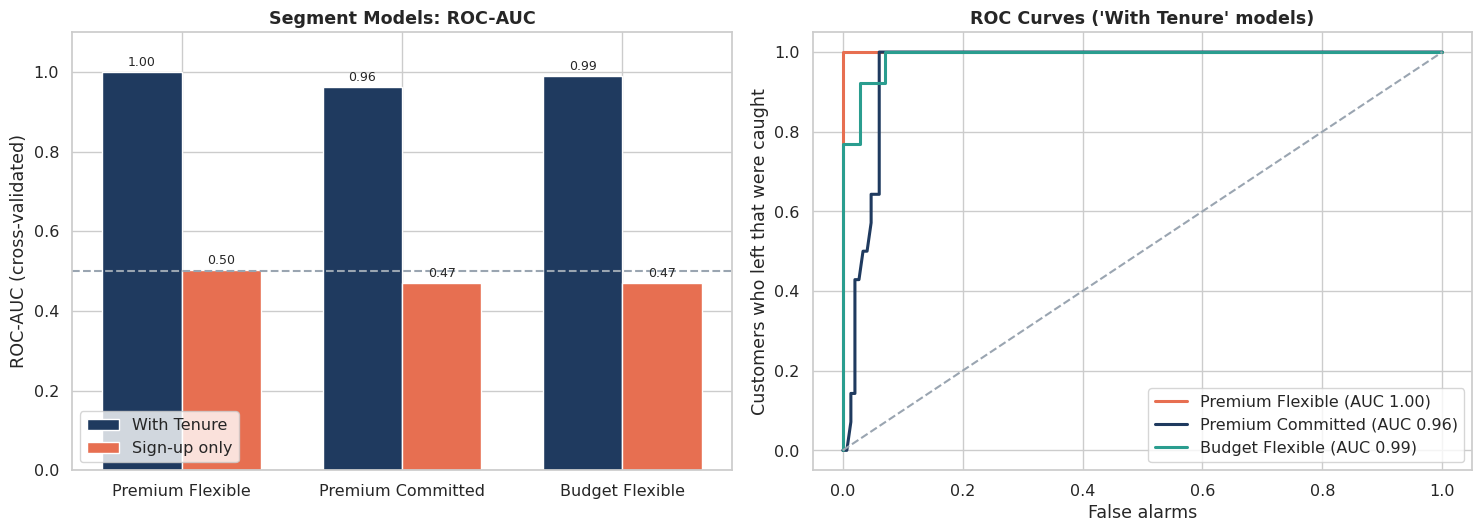

In [5]:
# Part 4: Separate prediction models for each segment and their evaluation (Days 4 and 5)

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)

# ---------- Prepare the prediction features ----------
payment = pd.get_dummies(df['PaymentMethod'], prefix='Pay', dtype=int)
model_data = pd.concat([df[['Tenure', 'MonthlyCharges', 'Contract_ordinal', 'SeniorCitizen',
                            'PaperlessBilling_binary']], payment], axis=1)
FEATURES_WITH = list(model_data.columns)                                    # includes Tenure
FEATURES_SIGNUP = [c for c in FEATURES_WITH if c != 'Tenure']               # only what is known at sign-up
y_all = df['Churn']
MIN_CHURNERS = 10                                                           # fewest churners needed to build a model

print("=" * 60)
print("WHICH SEGMENTS CAN GET THEIR OWN MODEL?")
print("=" * 60)
seg_counts = df.groupby('Segment')['Churn'].agg(['size', 'sum']).rename(columns={'size': 'Customers', 'sum': 'Churners'})
seg_counts['Own model?'] = np.where(seg_counts['Churners'] >= MIN_CHURNERS, 'Yes', 'No - too few churners')
print(seg_counts.sort_values('Churners', ascending=False).to_string())
MODEL_SEGMENTS = list(seg_counts[seg_counts['Churners'] >= MIN_CHURNERS].sort_values('Churners', ascending=False).index)
print(f"Rule: a segment needs at least {MIN_CHURNERS} customers who left, otherwise a model cannot learn or be tested reliably.")
print("Segments with a model:", MODEL_SEGMENTS)
skipped = [s for s in seg_counts.index if s not in MODEL_SEGMENTS]
for s in skipped:
    print(f"'{s}' has only {int(seg_counts.loc[s, 'Churners'])} churners, so it gets a simple watch-list rule instead of a model.")

# ---------- Model and evaluation settings ----------
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)           # keeps the churn share in every fold


def new_forest():
    return RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=42)


def metrics_from_predictions(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {'Accuracy': accuracy_score(y_true, pred),
            'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred, zero_division=0),
            'F1': f1_score(y_true, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_true, prob),
            'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}


# ---------- One model for everyone (to compare with the segment models) ----------
global_prob = {}
for label, feats in [('With Tenure', FEATURES_WITH), ('Sign-up only', FEATURES_SIGNUP)]:
    global_prob[label] = cross_val_predict(new_forest(), model_data[feats], y_all, cv=cv5, method='predict_proba')[:, 1]

# ---------- One model for each segment ----------
rows = []
segment_prob = {}
for seg in MODEL_SEGMENTS:
    idx = np.where(df['Segment'] == seg)[0]
    y_seg = y_all.iloc[idx]
    for label, feats in [('With Tenure', FEATURES_WITH), ('Sign-up only', FEATURES_SIGNUP)]:
        X_seg = model_data[feats].iloc[idx]
        prob = cross_val_predict(new_forest(), X_seg, y_seg, cv=cv5, method='predict_proba')[:, 1]   # predictions on unseen folds
        segment_prob[(seg, label)] = (y_seg.values, prob)
        fold_auc = cross_val_score(new_forest(), X_seg, y_seg, cv=cv5, scoring='roc_auc')
        m = metrics_from_predictions(y_seg.values, prob)
        rows.append({'Segment': seg, 'Model': 'Segment model', 'Features': label, 'Customers': len(idx),
                     'Churners': int(y_seg.sum()), **m, 'AUC std over folds': fold_auc.std()})
        g = metrics_from_predictions(y_seg.values, global_prob[label][idx])
        rows.append({'Segment': seg, 'Model': 'One model for all', 'Features': label, 'Customers': len(idx),
                     'Churners': int(y_seg.sum()), **g, 'AUC std over folds': np.nan})
results = pd.DataFrame(rows)

print()
print("=" * 60)
print("EVALUATION (5-fold cross-validation: every prediction is made on customers the model has NOT seen)")
print("=" * 60)
show = ['Segment', 'Model', 'Features', 'Customers', 'Churners', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC',
        'AUC std over folds']
print(results[show].round(3).to_string(index=False))
print()
print("Confusion matrix counts (TP = churners caught, FP = false alarms, FN = churners missed, TN = correct 'stay'):")
print(results[['Segment', 'Model', 'Features', 'TP', 'FP', 'FN', 'TN']].to_string(index=False))

print()
print("Baseline: always predicting 'stays' is right this often in each segment (but catches 0 churners):")
for seg in MODEL_SEGMENTS:
    rate = df.loc[df['Segment'] == seg, 'Churn'].mean()
    print(f"  {seg}: {(1 - rate) * 100:.1f}%")

print()
print("HOW TO READ THIS:")
print("  - ROC-AUC: 0.5 = guessing, 1.0 = perfect. Precision = how many alerts are real. Recall = how many churners are caught.")
print("  - 'With Tenure' scores are probably too high: Tenure may reveal the answer, because all customers who left")
print("    had a tenure of 11 months or less. 'Sign-up only' is the fair test for new customers.")
print("  - Each segment has only 13 to 23 churners, so scores can change a lot between folds (see 'AUC std over folds').")

# ---------- Chart ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
x = np.arange(len(MODEL_SEGMENTS))
for i, (label, color) in enumerate([('With Tenure', NAVY), ('Sign-up only', ORANGE)]):
    vals = [results[(results['Segment'] == s) & (results['Model'] == 'Segment model') & (results['Features'] == label)]['ROC-AUC'].iloc[0]
            for s in MODEL_SEGMENTS]
    bars = axes[0].bar(x + (i - 0.5) * 0.36, vals, 0.36, label=label, color=color)
    for b in bars:
        axes[0].annotate(f"{b.get_height():.2f}", (b.get_x() + b.get_width() / 2, b.get_height()), ha='center', va='bottom',
                         xytext=(0, 2), textcoords='offset points', fontsize=9)
axes[0].axhline(0.5, color=GREY, linestyle='--')
axes[0].set_xticks(x)
axes[0].set_xticklabels(MODEL_SEGMENTS)
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel('ROC-AUC (cross-validated)')
axes[0].set_title('Segment Models: ROC-AUC', fontweight='bold')
axes[0].legend(loc='lower left')
for seg, color in zip(MODEL_SEGMENTS, [ORANGE, NAVY, TEAL]):
    y_true, prob = segment_prob[(seg, 'With Tenure')]
    fpr, tpr, _ = roc_curve(y_true, prob)
    axes[1].plot(fpr, tpr, linewidth=2.2, color=color, label=f"{seg} (AUC {roc_auc_score(y_true, prob):.2f})")
axes[1].plot([0, 1], [0, 1], color=GREY, linestyle='--')
axes[1].set_title("ROC Curves ('With Tenure' models)", fontweight='bold')
axes[1].set_xlabel('False alarms')
axes[1].set_ylabel('Customers who left that were caught')
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/6_segment_models.png', dpi=150, bbox_inches='tight')
plt.show()

GRID SEARCH SETUP
Settings tried: {'n_estimators': [100, 200], 'max_depth': [3, None], 'min_samples_leaf': [1, 3]}
8 combinations x 3 inner folds = 24 model fits for every search.
Tuning goal: the best F1-score (catch churners without too many false alarms).

Honest testing: the search runs INSIDE each of the 5 outer folds, so the customers used to
test a model are never used to choose its settings (this is called nested cross-validation).
Please wait about 2 to 4 minutes...

DEFAULT SETTINGS vs TUNED SETTINGS (5-fold cross-validation)
          Segment     Features  F1 default  F1 tuned  Recall default  Recall tuned  Precision default  Precision tuned  ROC-AUC default  ROC-AUC tuned
 Premium Flexible  With Tenure       1.000     1.000           1.000         1.000              1.000            1.000            1.000          1.000
 Premium Flexible Sign-up only       0.244     0.133           0.217         0.130              0.278            0.136            0.503          0.471
Premi

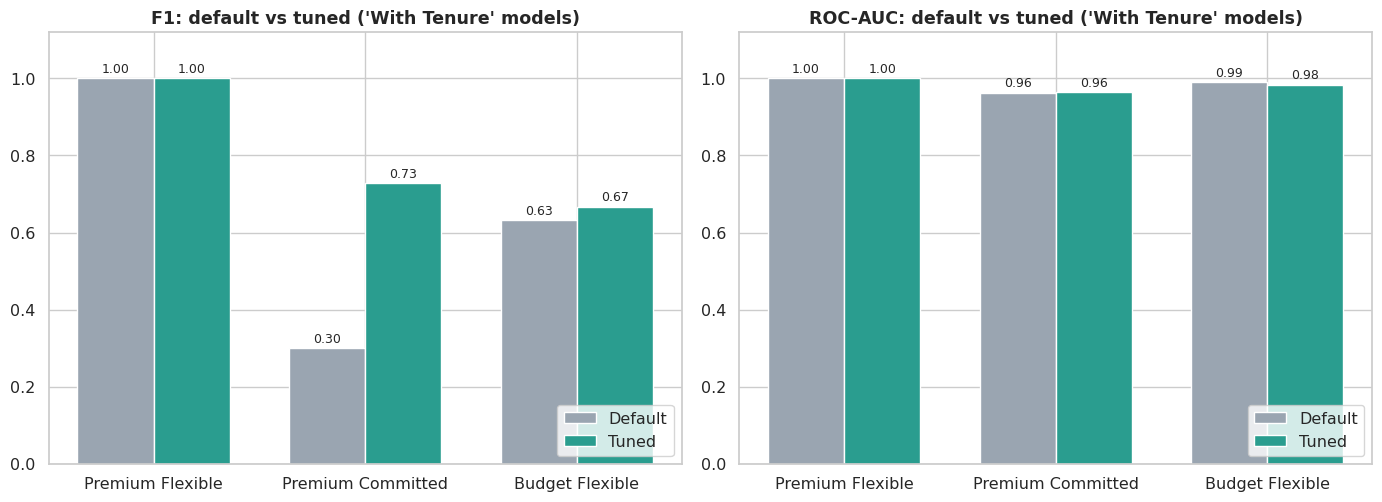

FEATURE IMPORTANCE (tuned 'With Tenure' model of each segment)


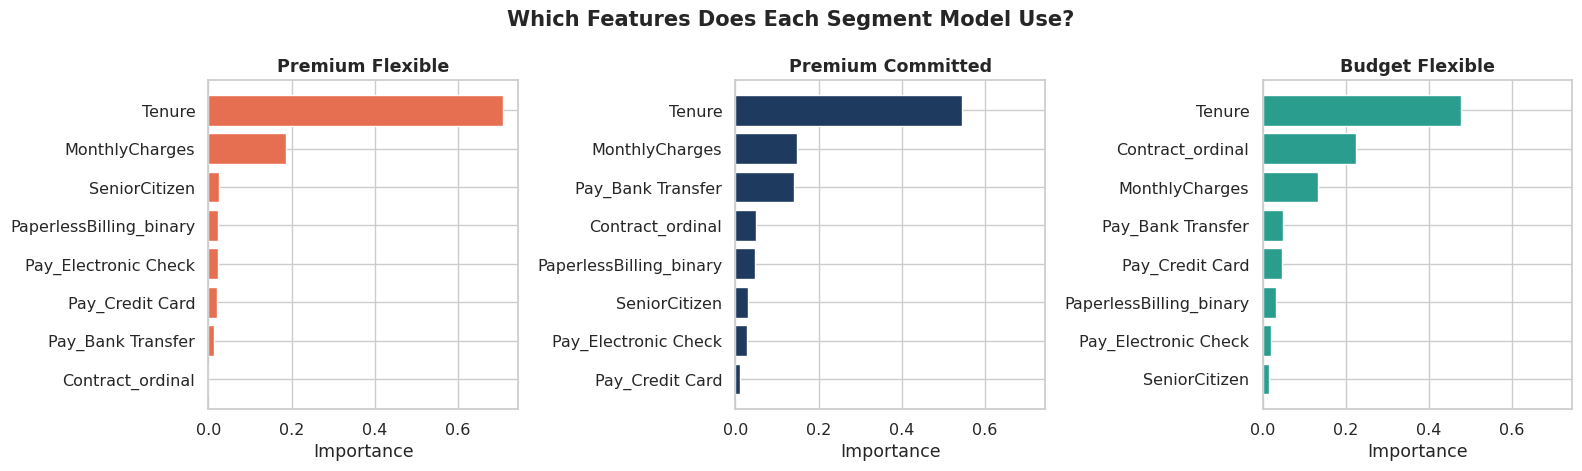

Premium Flexible: Tenure (0.71), MonthlyCharges (0.19), SeniorCitizen (0.03)
Premium Committed: Tenure (0.55), MonthlyCharges (0.15), Pay_Bank Transfer (0.14)
Budget Flexible: Tenure (0.48), Contract_ordinal (0.22), MonthlyCharges (0.13)
Tenure is the top feature in every segment. This matches the warning about Tenure: it is a strong signal,
but it may partly reveal the answer, so these models describe the past better than they predict new customers.

Saved model_evaluation_results.csv with 19 rows


In [6]:

# Part 5: Hyperparameter tuning with Grid Search (Day 6) and feature importance

from sklearn.model_selection import GridSearchCV

# ---------- The settings (hyperparameters) to try ----------
param_grid = {'n_estimators': [100, 200],        # number of trees
              'max_depth': [3, None],            # how deep each tree may grow (None = no limit)
              'min_samples_leaf': [1, 3]}        # smallest group a tree may split off
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)


def tuned_search():
    forest = RandomForestClassifier(class_weight='balanced_subsample', random_state=42)
    return GridSearchCV(forest, param_grid, scoring='f1', cv=inner_cv, n_jobs=-1)       # F1 balances catching churners and false alarms


combos = 1
for v in param_grid.values():
    combos *= len(v)
print("=" * 60)
print("GRID SEARCH SETUP")
print("=" * 60)
print("Settings tried:", param_grid)
print(f"{combos} combinations x 3 inner folds = {combos * 3} model fits for every search.")
print("Tuning goal: the best F1-score (catch churners without too many false alarms).")
print()
print("Honest testing: the search runs INSIDE each of the 5 outer folds, so the customers used to")
print("test a model are never used to choose its settings (this is called nested cross-validation).")
print("Please wait about 2 to 4 minutes...")

tuned_rows = []
best_settings = {}
for seg in MODEL_SEGMENTS:
    idx = np.where(df['Segment'] == seg)[0]
    y_seg = y_all.iloc[idx]
    for label, feats in [('With Tenure', FEATURES_WITH), ('Sign-up only', FEATURES_SIGNUP)]:
        X_seg = model_data[feats].iloc[idx]
        prob = cross_val_predict(tuned_search(), X_seg, y_seg, cv=cv5, method='predict_proba')[:, 1]
        m = metrics_from_predictions(y_seg.values, prob)
        tuned_rows.append({'Segment': seg, 'Model': 'Segment model (tuned)', 'Features': label, 'Customers': len(idx),
                           'Churners': int(y_seg.sum()), **m, 'AUC std over folds': np.nan})
        final = tuned_search().fit(X_seg, y_seg)                      # settings to use for the final model
        best_settings[(seg, label)] = (final.best_params_, final.best_score_)
tuned = pd.DataFrame(tuned_rows)

# ---------- Default settings against tuned settings ----------
default = results[results['Model'] == 'Segment model']
compare_rows = []
for _, t in tuned.iterrows():
    d = default[(default['Segment'] == t['Segment']) & (default['Features'] == t['Features'])].iloc[0]
    compare_rows.append({'Segment': t['Segment'], 'Features': t['Features'],
                         'F1 default': d['F1'], 'F1 tuned': t['F1'],
                         'Recall default': d['Recall'], 'Recall tuned': t['Recall'],
                         'Precision default': d['Precision'], 'Precision tuned': t['Precision'],
                         'ROC-AUC default': d['ROC-AUC'], 'ROC-AUC tuned': t['ROC-AUC']})
compare = pd.DataFrame(compare_rows)

print()
print("=" * 60)
print("DEFAULT SETTINGS vs TUNED SETTINGS (5-fold cross-validation)")
print("=" * 60)
print(compare.round(3).to_string(index=False))

print()
print("=" * 60)
print("BEST SETTINGS FOUND (search on the whole segment)")
print("=" * 60)
for (seg, label), (params, score) in best_settings.items():
    print(f"{seg} | {label}: {params} (search F1 = {score:.3f})")

improved = int((compare['F1 tuned'] > compare['F1 default'] + 0.005).sum())
same = int(((compare['F1 tuned'] - compare['F1 default']).abs() <= 0.005).sum())
worse = int((compare['F1 tuned'] < compare['F1 default'] - 0.005).sum())
print()
print(f"F1 compared with the default settings: better in {improved} cases, about the same in {same}, worse in {worse}.")
signup_auc = compare.loc[compare['Features'] == 'Sign-up only', 'ROC-AUC tuned']
print("Tuning cannot create information that is not in the data.")
print(f"'Sign-up only' ROC-AUC after tuning: {signup_auc.min():.2f} to {signup_auc.max():.2f} (0.5 = guessing).")
print("With only 13 to 23 churners per segment, differences like these are mostly chance, not a real signal.")

# ---------- Chart: default vs tuned for the 'With Tenure' models ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
x = np.arange(len(MODEL_SEGMENTS))
sub = compare[compare['Features'] == 'With Tenure'].set_index('Segment').loc[MODEL_SEGMENTS]
for ax, metric in zip(axes, ['F1', 'ROC-AUC']):
    for i, (kind, color) in enumerate([('default', GREY), ('tuned', TEAL)]):
        vals = sub[f'{metric} {kind}'].values
        bars = ax.bar(x + (i - 0.5) * 0.36, vals, 0.36, label=kind.capitalize(), color=color)
        for b in bars:
            ax.annotate(f"{b.get_height():.2f}", (b.get_x() + b.get_width() / 2, b.get_height()), ha='center', va='bottom',
                        xytext=(0, 2), textcoords='offset points', fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_SEGMENTS)
    ax.set_ylim(0, 1.12)
    ax.set_title(f"{metric}: default vs tuned ('With Tenure' models)", fontweight='bold')
    ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/7_tuning_results.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Feature importance: what does each segment model use? ----------
print("=" * 60)
print("FEATURE IMPORTANCE (tuned 'With Tenure' model of each segment)")
print("=" * 60)
fig, axes = plt.subplots(1, len(MODEL_SEGMENTS), figsize=(16, 4.8), sharex=True)
importance_table = {}
for ax, seg, color in zip(axes, MODEL_SEGMENTS, [ORANGE, NAVY, TEAL]):
    idx = np.where(df['Segment'] == seg)[0]
    params, _ = best_settings[(seg, 'With Tenure')]
    model = RandomForestClassifier(class_weight='balanced_subsample', random_state=42, **params)
    model.fit(model_data[FEATURES_WITH].iloc[idx], y_all.iloc[idx])
    imp = pd.Series(model.feature_importances_, index=FEATURES_WITH).sort_values()
    importance_table[seg] = imp.sort_values(ascending=False)
    ax.barh(imp.index, imp.values, color=color)
    ax.set_title(seg, fontweight='bold')
    ax.set_xlabel('Importance')
plt.suptitle('Which Features Does Each Segment Model Use?', fontweight='bold')
plt.tight_layout()
plt.savefig('figures/8_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
for seg, imp in importance_table.items():
    top = ", ".join(f"{k} ({v:.2f})" for k, v in imp.head(3).items())
    print(f"{seg}: {top}")
if all(imp.index[0] == 'Tenure' for imp in importance_table.values()):
    print("Tenure is the top feature in every segment. This matches the warning about Tenure: it is a strong signal,")
    print("but it may partly reveal the answer, so these models describe the past better than they predict new customers.")
else:
    print("Tenure-based information matters most in these models. It may partly reveal the answer (see the warning in Part 4).")

# ---------- Save the evaluation results (a required file) ----------
all_results = pd.concat([results[results['Model'] == 'Segment model'], tuned, results[results['Model'] == 'One model for all']],
                        ignore_index=True)
all_results.loc[all_results['Model'] == 'Segment model', 'Model'] = 'Segment model (default settings)'
for s in skipped:
    all_results.loc[len(all_results)] = {'Segment': s, 'Model': 'No model (too few churners)', 'Features': 'n/a',
                                         'Customers': int(seg_counts.loc[s, 'Customers']), 'Churners': int(seg_counts.loc[s, 'Churners'])}
all_results.round(4).to_csv('model_evaluation_results.csv', index=False)
print()
print("Saved model_evaluation_results.csv with", len(all_results), "rows")

WHERE THE CHURN IS: FIRST-YEAR CUSTOMERS IN EACH SEGMENT
                   First_year_customers  Left  Avg_charge  First-year churn rate %  Customers after year 1  Left after year 1
Segment                                                                                                                      
Premium Flexible                     23    23       152.7                    100.0                      77                  0
Premium Committed                    23    14       159.2                     60.9                     139                  0
Budget Flexible                      26    13        65.4                     50.0                     130                  0
Budget Committed                     11     3        70.7                     27.3                      71                  0
No customer who has been with the company 12 months or more has left, in any segment.

BREAK-EVEN: HOW MANY WOULD-BE LEAVERS MUST A PROGRAMME KEEP TO PAY FOR ITSELF?
Cost level         Lo

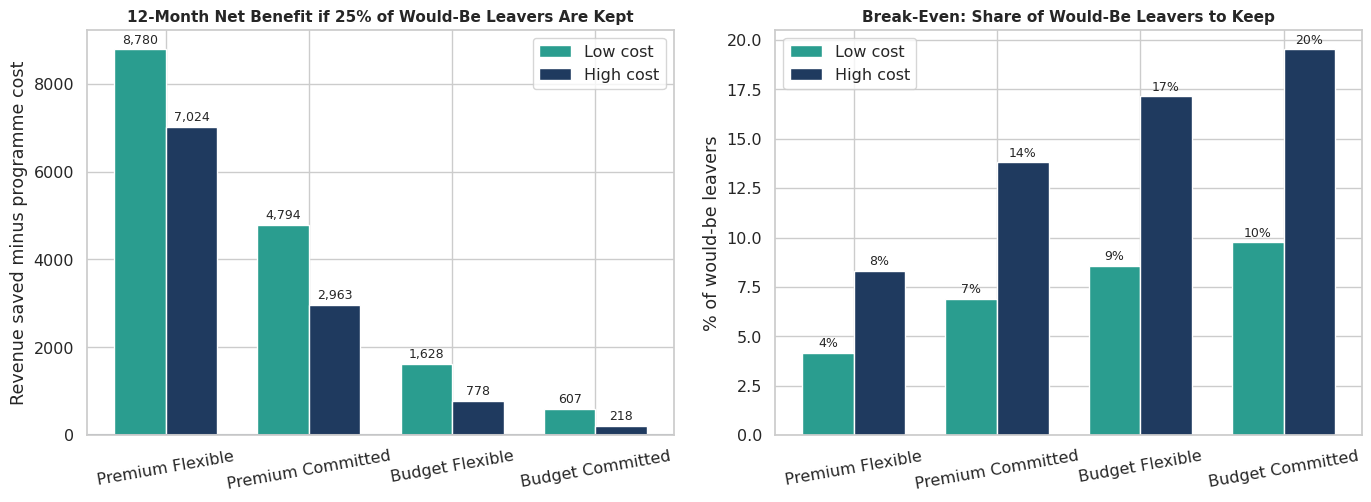

SUMMARY FOR THE BUSINESS
1. Churn is concentrated: Premium Flexible has 23% churn and 51% of the lost revenue.
2. All churn happens in the first year, in every segment. Contact customers early.
3. Models with Tenure are very accurate, but Tenure may reveal the answer; models using only sign-up
   information do no better than guessing. Use the segments to decide WHO to contact, not a score to predict new customers.
4. Start with a pilot (with a control group) in the highest-priority segments and measure the real effect.


In [7]:
# Part 6: Business insights and recommendations (Day 7)
# IMPORTANT: the money figures use ASSUMPTIONS (marked below). The data has no information about what a
# retention programme costs or how well it works, so these are scenarios, not forecasts.

# ---------- Assumptions you can change ----------
CHURN_REDUCTIONS = [0.10, 0.25, 0.40]                  # share of would-be leavers the programme manages to keep
COST_FACTORS = {'Low cost': 0.5, 'High cost': 1.0}     # programme cost per enrolled customer, as a multiple of one month's charge
VALUE_MONTHS = 12                                      # a saved customer is worth 12 months of charges (cautious)

# ---------- Who should be contacted? Customers in their first year (all customers who left were in month 11 or earlier) ----------
df['FirstYear'] = (df['Tenure'] <= 11).astype(int)
seg_order = list(profiles.index)                       # from highest to lowest churn rate

print("=" * 60)
print("WHERE THE CHURN IS: FIRST-YEAR CUSTOMERS IN EACH SEGMENT")
print("=" * 60)
fy = df[df['FirstYear'] == 1].groupby('Segment').agg(First_year_customers=('Churn', 'size'), Left=('Churn', 'sum'),
                                                     Avg_charge=('MonthlyCharges', 'mean'))
fy['First-year churn rate %'] = fy['Left'] / fy['First_year_customers'] * 100
later = df[df['FirstYear'] == 0].groupby('Segment')['Churn'].agg(['size', 'sum'])
fy['Customers after year 1'] = later['size']
fy['Left after year 1'] = later['sum']
print(fy.loc[seg_order].round(1).to_string())
print("No customer who has been with the company 12 months or more has left, in any segment.")

# ---------- Business impact scenarios per segment ----------
rows = []
for seg in seg_order:
    g = df[(df['Segment'] == seg) & (df['FirstYear'] == 1)]            # customers the programme would contact
    leavers = g[g['Churn'] == 1]
    if len(leavers) == 0:
        continue
    value_each = leavers['MonthlyCharges'].mean() * VALUE_MONTHS
    for reduction in CHURN_REDUCTIONS:
        for level, factor in COST_FACTORS.items():
            saved = len(leavers) * reduction
            revenue_saved = saved * value_each
            cost = len(g) * factor * g['MonthlyCharges'].mean()
            rows.append({'Segment': seg, 'Enrolled': len(g), 'Would-be leavers': len(leavers), 'Churn reduction': reduction,
                         'Cost level': level, 'Customers saved': saved, 'Revenue saved': revenue_saved,
                         'Programme cost': cost, 'Net benefit': revenue_saved - cost,
                         'Break-even %': cost / (len(leavers) * value_each) * 100})
impact = pd.DataFrame(rows)

print()
print("=" * 60)
print("BREAK-EVEN: HOW MANY WOULD-BE LEAVERS MUST A PROGRAMME KEEP TO PAY FOR ITSELF?")
print("=" * 60)
be = impact.groupby(['Segment', 'Cost level'])['Break-even %'].first().unstack()[['Low cost', 'High cost']]
be['Enrolled'] = impact.groupby('Segment')['Enrolled'].first()
be['Would-be leavers'] = impact.groupby('Segment')['Would-be leavers'].first()
print(be.loc[[s for s in seg_order if s in be.index]].round(1).to_string())
print("Assumed cost: 0.5 (low) or 1.0 (high) month of charges per contacted customer. A saved customer is worth 12 months of charges.")

print()
print("=" * 60)
print("12-MONTH NET BENEFIT IF THE PROGRAMME KEEPS 25% OF WOULD-BE LEAVERS")
print("=" * 60)
mid = impact[impact['Churn reduction'] == 0.25].pivot(index='Segment', columns='Cost level', values='Net benefit')[['Low cost', 'High cost']]
print(mid.loc[[s for s in seg_order if s in mid.index]].round(0).to_string())
total_mid = mid.sum()
print(f"All segments together: {total_mid['Low cost']:,.0f} (low cost) to {total_mid['High cost']:,.0f} (high cost)")
print("These are scenarios, not forecasts. A pilot with a control group must measure the real effect.")
for s_name in skipped:
    print(f"Note: {s_name} has only {int(seg_counts.loc[s_name, 'Churners'])} customers who left, so its numbers are very rough.")

# ---------- Watch-list for the segment without a model ----------
watch = df[(df['Segment'].isin(skipped)) & (df['FirstYear'] == 1)]
print()
print("=" * 60)
print("WATCH-LIST FOR SEGMENTS WITHOUT A MODEL")
print("=" * 60)
for s in skipped:
    w = watch[watch['Segment'] == s]
    print(f"{s}: contact the {len(w)} customers in their first year; only {int(df.loc[df['Segment'] == s, 'Churn'].sum())} customers have ever left from this segment.")

# ---------- Segment strategies ----------
strategies = pd.DataFrame([
    ['Premium Flexible', 'Highest priority',
     'Offer a discount to move from month-to-month to a one-year contract; welcome call in week 1; account check-in at month 3',
     'Share on a contract; first-year churn rate', 'Cut first-year churn by a quarter'],
    ['Premium Committed', 'High value, medium risk',
     'Check-in before the first renewal; loyalty benefit for customers passing month 12; fix any billing questions',
     'First-year churn rate; renewal rate', 'Keep churn under 8%'],
    ['Budget Flexible', 'Medium risk, low cost',
     'Low-cost automated messages in the first year; small offer to move to a one-year contract',
     'Cost per contacted customer; share on a contract', 'Positive net benefit per 100 customers'],
    ['Budget Committed', 'Low risk',
     'No programme; watch-list of first-year customers; keep service quality high',
     'Churn rate', 'Stay below 5%']],
    columns=['Segment', 'Priority', 'Actions', 'Measure', 'Target'])
print()
print("=" * 60)
print("RECOMMENDED STRATEGY FOR EACH SEGMENT")
print("=" * 60)
for _, r in strategies.iterrows():
    print(f"{r['Segment']} ({r['Priority']})\n   Actions: {r['Actions']}\n   Measure: {r['Measure']}  ->  Target: {r['Target']}\n")

# ---------- Chart ----------
seg_in_chart = [s for s in seg_order if s in be.index]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
x = np.arange(len(seg_in_chart))
for i, (level, color) in enumerate([('Low cost', TEAL), ('High cost', NAVY)]):
    bars = axes[0].bar(x + (i - 0.5) * 0.36, mid.loc[seg_in_chart, level], 0.36, label=level, color=color)
    for b in bars:
        axes[0].annotate(f"{b.get_height():,.0f}", (b.get_x() + b.get_width() / 2, b.get_height()), ha='center',
                         va='bottom' if b.get_height() >= 0 else 'top', xytext=(0, 2), textcoords='offset points', fontsize=9)
axes[0].axhline(0, color=GREY)
axes[0].set_xticks(x)
axes[0].set_xticklabels(seg_in_chart, rotation=10)
axes[0].set_title('12-Month Net Benefit if 25% of Would-Be Leavers Are Kept', fontweight='bold', fontsize=11)
axes[0].set_ylabel('Revenue saved minus programme cost')
axes[0].legend()
for i, (level, color) in enumerate([('Low cost', TEAL), ('High cost', NAVY)]):
    bars = axes[1].bar(x + (i - 0.5) * 0.36, be.loc[seg_in_chart, level], 0.36, label=level, color=color)
    for b in bars:
        axes[1].annotate(f"{b.get_height():.0f}%", (b.get_x() + b.get_width() / 2, b.get_height()), ha='center', va='bottom',
                         xytext=(0, 2), textcoords='offset points', fontsize=9)
axes[1].set_xticks(x)
axes[1].set_xticklabels(seg_in_chart, rotation=10)
axes[1].set_title('Break-Even: Share of Would-Be Leavers to Keep', fontweight='bold', fontsize=11)
axes[1].set_ylabel('% of would-be leavers')
axes[1].legend()
plt.tight_layout()
plt.savefig('figures/9_business_impact.png', dpi=150, bbox_inches='tight')
plt.show()

print("=" * 60)
print("SUMMARY FOR THE BUSINESS")
print("=" * 60)
top = seg_order[0]
print(f"1. Churn is concentrated: {top} has {profiles.loc[top, 'Churn rate %']:.0f}% churn and {profiles.loc[top, 'Share of revenue lost %']:.0f}% of the lost revenue.")
print("2. All churn happens in the first year, in every segment. Contact customers early.")
print("3. Models with Tenure are very accurate, but Tenure may reveal the answer; models using only sign-up")
print("   information do no better than guessing. Use the segments to decide WHO to contact, not a score to predict new customers.")
print("4. Start with a pilot (with a control group) in the highest-priority segments and measure the real effect.")